In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
# Load the cleaned Sri Lankan weather dataset

df = pd.read_csv("dataset/cleaned_weather.csv")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset shape: (65390, 9)


,date,city,latitude,longitude,temp_max_c,temp_min_c,precipitation_mm,wind_speed_max_kmh,humidity_mean_pct
0,2020-01-01,Ampara,7.2975,81.6820,30.0,23.7,3.4,13.7,87
1,2020-01-01,Anuradhapura,8.3114,80.4037,30.1,23.2,1.3,14.1,87
2,2020-01-01,Badulla,6.9934,81.0550,26.7,18.7,1.6,7.2,85
3,2020-01-01,Batticaloa,7.7310,81.6747,29.6,24.6,2.9,18.0,85
4,2020-01-01,Colombo,6.9271,79.8612,29.0,24.2,1.1,11.0,88


In [3]:
# Display dataset information

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 65390 entries, 0 to 65389
Data columns (total 9 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   date                65390 non-null  str    
 1   city                65390 non-null  str    
 2   latitude            65390 non-null  float64
 3   longitude           65390 non-null  float64
 4   temp_max_c          65390 non-null  float64
 5   temp_min_c          65390 non-null  float64
 6   precipitation_mm    65390 non-null  float64
 7   wind_speed_max_kmh  65390 non-null  float64
 8   humidity_mean_pct   65390 non-null  int64  
dtypes: float64(6), int64(1), str(2)
memory usage: 5.6 MB


In [4]:
# Check missing values
print("Missing Values:")
print(df.isnull().sum())

# Check duplicate records
print("\nDuplicate Records:")
print(df.duplicated().sum())

Missing Values:
date                  0
city                  0
latitude              0
longitude             0
temp_max_c            0
temp_min_c            0
precipitation_mm      0
wind_speed_max_kmh    0
humidity_mean_pct     0
dtype: int64

Duplicate Records:
0


In [5]:
# Convert date column to datetime format

df["date"] = pd.to_datetime(df["date"])

print("Date column converted successfully!")
print("Date data type:", df["date"].dtype)

df.head()

Date column converted successfully!
Date data type: datetime64[us]


,date,city,latitude,longitude,temp_max_c,temp_min_c,precipitation_mm,wind_speed_max_kmh,humidity_mean_pct
0,2020-01-01,Ampara,7.2975,81.6820,30.0,23.7,3.4,13.7,87
1,2020-01-01,Anuradhapura,8.3114,80.4037,30.1,23.2,1.3,14.1,87
2,2020-01-01,Badulla,6.9934,81.0550,26.7,18.7,1.6,7.2,85
3,2020-01-01,Batticaloa,7.7310,81.6747,29.6,24.6,2.9,18.0,85
4,2020-01-01,Colombo,6.9271,79.8612,29.0,24.2,1.1,11.0,88


In [6]:
# Statistical summary of numerical columns

df.describe()

,date,latitude,longitude,temp_max_c,temp_min_c,precipitation_mm,wind_speed_max_kmh,humidity_mean_pct
count,65390,65390.000000,65390.000000,65390.000000,65390.000000,65390.000000,65390.000000,65390.000000
mean,2023-06-11 00:00:00,7.554385,80.608458,30.194098,23.438293,5.778893,17.626258,80.339134
min,2020-01-01 00:00:00,5.954900,79.828300,14.700000,5.800000,0.000000,3.300000,41.000000
25%,2021-09-20 00:00:00,6.872800,80.221000,28.700000,22.500000,0.300000,12.700000,75.000000
50%,2023-06-11 00:00:00,7.294050,80.526050,30.200000,23.900000,1.900000,16.700000,81.000000
75%,2025-03-01 00:00:00,8.311400,81.055000,32.100000,25.100000,6.900000,21.400000,87.000000
max,2026-11-19 00:00:00,9.661500,81.682000,40.400000,30.400000,321.800000,76.000000,100.000000
std,NaN,1.027365,0.532904,3.305673,2.918546,10.577716,6.819608,8.342364


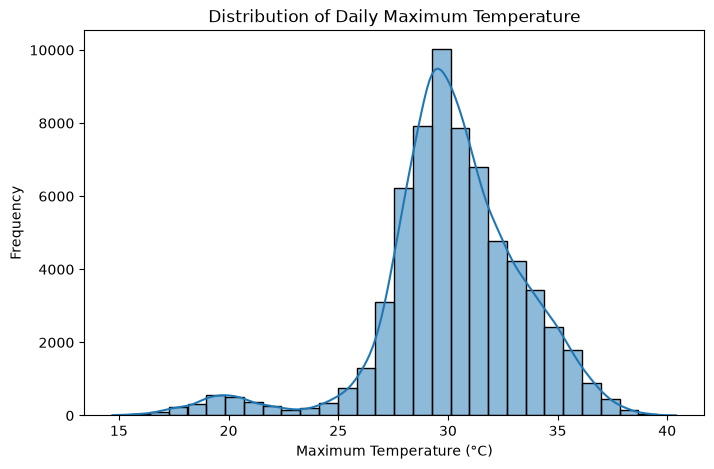

In [7]:
# Distribution of Maximum Temperature

plt.figure(figsize=(8, 5))
sns.histplot(df["temp_max_c"], bins=30, kde=True)

plt.title("Distribution of Daily Maximum Temperature")
plt.xlabel("Maximum Temperature (°C)")
plt.ylabel("Frequency")
plt.show()

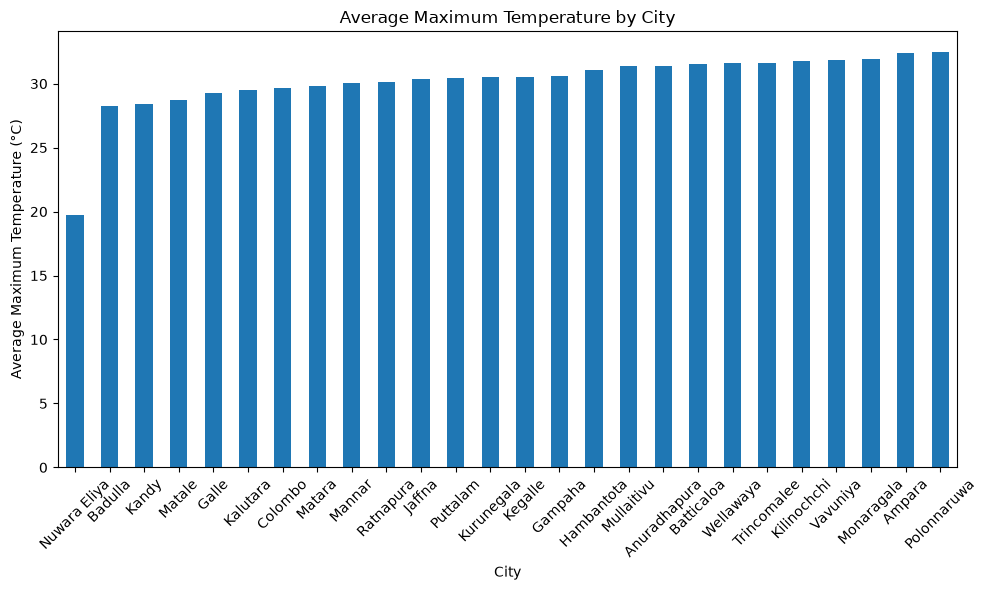

In [8]:
# Average Maximum Temperature by City

city_temp = df.groupby("city")["temp_max_c"].mean().sort_values()

plt.figure(figsize=(10, 6))
city_temp.plot(kind="bar")

plt.title("Average Maximum Temperature by City")
plt.xlabel("City")
plt.ylabel("Average Maximum Temperature (°C)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

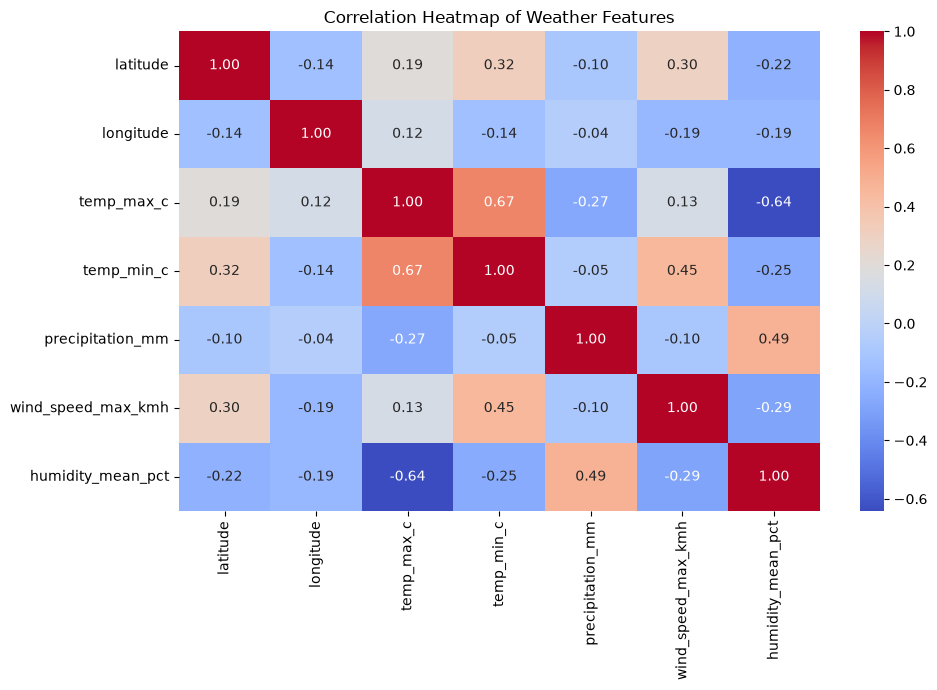

In [9]:
# Correlation Heatmap

numeric_df = df.select_dtypes(include="number")

plt.figure(figsize=(10, 7))
sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap of Weather Features")
plt.tight_layout()
plt.show()

In [10]:
# Define features and target

df["year"] = df["date"].dt.year
df["month"] = df["date"].dt.month
df["day"] = df["date"].dt.day
df["day_of_year"] = df["date"].dt.day_of_year

features = [
    "city",
    "latitude",
    "longitude",
    "temp_min_c",
    "precipitation_mm",
    "wind_speed_max_kmh",
    "humidity_mean_pct",
    "year",
    "month",
    "day",
    "day_of_year"
]

X = df[features]
y = df["temp_max_c"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)
print("\nFeature columns:")
print(X.columns.tolist())

Features shape: (65390, 11)
Target shape: (65390,)

Feature columns:
['city', 'latitude', 'longitude', 'temp_min_c', 'precipitation_mm', 'wind_speed_max_kmh', 'humidity_mean_pct', 'year', 'month', 'day', 'day_of_year']


In [12]:
# Split data into training and testing sets

unique_dates = np.sort(df["date"].unique())
split_index = int(len(unique_dates) * 0.8)

train_dates = unique_dates[:split_index]
test_dates = unique_dates[split_index:]

train_mask = df["date"].isin(train_dates)
test_mask = df["date"].isin(test_dates)

X_train = X.loc[train_mask]
X_test = X.loc[test_mask]

y_train = y.loc[train_mask]
y_test = y.loc[test_mask]

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)
print("Training date range:", train_dates[0], "to", train_dates[-1])
print("Testing date range:", test_dates[0], "to", test_dates[-1])

Training data: (52312, 11)
Testing data: (13078, 11)
Training date range: 2020-01-01T00:00:00.000000 to 2025-07-04T00:00:00.000000
Testing date range: 2025-07-05T00:00:00.000000 to 2026-11-19T00:00:00.000000


In [13]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline

categorical_features = ["city"]

numerical_features = [
    "latitude",
    "longitude",
    "temp_min_c",
    "precipitation_mm",
    "wind_speed_max_kmh",
    "humidity_mean_pct",
    "year",
    "month",
    "day",
    "day_of_year"
]

preprocessor = ColumnTransformer(
    transformers=[
        ("city", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ],
    remainder="passthrough"
)

print("Preprocessing setup completed!")

Preprocessing setup completed!


In [14]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Create Random Forest pipeline
rf_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestRegressor(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ))
])

# Train the model
rf_model.fit(X_train, y_train)

# Make predictions
rf_predictions = rf_model.predict(X_test)

# Evaluate the model
rf_mae = mean_absolute_error(y_test, rf_predictions)
rf_rmse = np.sqrt(mean_squared_error(y_test, rf_predictions))
rf_r2 = r2_score(y_test, rf_predictions)

print("Random Forest Results")
print("MAE:", round(rf_mae, 3))
print("RMSE:", round(rf_rmse, 3))
print("R2 Score:", round(rf_r2, 3))

Random Forest Results
MAE: 0.839
RMSE: 1.093
R2 Score: 0.892


In [15]:
from xgboost import XGBRegressor

# Create XGBoost pipeline
xgb_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", XGBRegressor(
        n_estimators=100,
        learning_rate=0.1,
        max_depth=6,
        random_state=42,
        n_jobs=-1
    ))
])

# Train the model
xgb_model.fit(X_train, y_train)

# Make predictions
xgb_predictions = xgb_model.predict(X_test)

# Evaluate the model
xgb_mae = mean_absolute_error(y_test, xgb_predictions)
xgb_rmse = np.sqrt(mean_squared_error(y_test, xgb_predictions))
xgb_r2 = r2_score(y_test, xgb_predictions)

print("XGBoost Results")
print("MAE:", round(xgb_mae, 3))
print("RMSE:", round(xgb_rmse, 3))
print("R2 Score:", round(xgb_r2, 3))

XGBoost Results
MAE: 0.818
RMSE: 1.063
R2 Score: 0.898


In [16]:
from lightgbm import LGBMRegressor

# Create LightGBM pipeline
lgbm_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LGBMRegressor(
        n_estimators=100,
        learning_rate=0.1,
        random_state=42,
        n_jobs=-1,
        verbosity=-1
    ))
])

# Train the model
lgbm_model.fit(X_train, y_train)

# Make predictions
lgbm_predictions = lgbm_model.predict(X_test)

# Evaluate the model
lgbm_mae = mean_absolute_error(y_test, lgbm_predictions)
lgbm_rmse = np.sqrt(mean_squared_error(y_test, lgbm_predictions))
lgbm_r2 = r2_score(y_test, lgbm_predictions)

print("LightGBM Results")
print("MAE:", round(lgbm_mae, 3))
print("RMSE:", round(lgbm_rmse, 3))
print("R2 Score:", round(lgbm_r2, 3))

LightGBM Results
MAE: 0.819
RMSE: 1.062
R2 Score: 0.898


In [17]:
from catboost import CatBoostRegressor

# Create CatBoost pipeline
cat_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", CatBoostRegressor(
        iterations=100,
        learning_rate=0.1,
        depth=6,
        random_seed=42,
        verbose=0
    ))
])

# Train the model
cat_model.fit(X_train, y_train)

# Make predictions
cat_predictions = cat_model.predict(X_test)

# Evaluate the model
cat_mae = mean_absolute_error(y_test, cat_predictions)
cat_rmse = np.sqrt(mean_squared_error(y_test, cat_predictions))
cat_r2 = r2_score(y_test, cat_predictions)

print("CatBoost Results")
print("MAE:", round(cat_mae, 3))
print("RMSE:", round(cat_rmse, 3))
print("R2 Score:", round(cat_r2, 3))

CatBoost Results
MAE: 0.858
RMSE: 1.109
R2 Score: 0.889


In [92]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import Ridge
from sklearn.model_selection import TimeSeriesSplit
from sklearn.base import clone

# Define base models
base_models = [
    ("rf", RandomForestRegressor(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    )),
    ("xgb", XGBRegressor(
        n_estimators=100,
        learning_rate=0.1,
        max_depth=6,
        random_state=42,
        n_jobs=-1
    )),
    ("lgbm", LGBMRegressor(
        n_estimators=100,
        learning_rate=0.1,
        random_state=42,
        n_jobs=-1,
        verbosity=-1
    ))
]

# Fit preprocessing using training data only
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

# Generate time-based out-of-fold predictions
tscv = TimeSeriesSplit(n_splits=3)

oof_predictions = np.full(
    (len(X_train), len(base_models)),
    np.nan
)

for train_idx, valid_idx in tscv.split(X_train_processed):

    for model_idx, (name, model) in enumerate(base_models):

        model_clone = clone(model)

        model_clone.fit(
            X_train_processed[train_idx],
            y_train.iloc[train_idx]
        )

        oof_predictions[valid_idx, model_idx] = model_clone.predict(
            X_train_processed[valid_idx]
        )

# Train meta-model using valid out-of-fold predictions
valid_rows = ~np.isnan(oof_predictions).any(axis=1)

meta_model = Ridge()
meta_model.fit(
    oof_predictions[valid_rows],
    y_train.iloc[np.where(valid_rows)[0]]
)

# Retrain base models using the complete training dataset
trained_base_models = []

for name, model in base_models:

    model_clone = clone(model)
    model_clone.fit(X_train_processed, y_train)

    trained_base_models.append((name, model_clone))

# Generate test predictions from base models
test_base_predictions = np.column_stack([
    model.predict(X_test_processed)
    for name, model in trained_base_models
])

# Final stacking predictions
stacking_predictions = meta_model.predict(test_base_predictions)

# Evaluate the model
stacking_mae = mean_absolute_error(y_test, stacking_predictions)
stacking_rmse = np.sqrt(mean_squared_error(y_test, stacking_predictions))
stacking_r2 = r2_score(y_test, stacking_predictions)

print("Time-Based Stacking Results")
print("MAE:", round(stacking_mae, 3))
print("RMSE:", round(stacking_rmse, 3))
print("R2 Score:", round(stacking_r2, 3))

Time-Based Stacking Results
MAE: 0.806
RMSE: 1.045
R2 Score: 0.901


In [119]:
import joblib

# Save the updated time-based stacking model components
stacking_bundle = {
    "preprocessor": preprocessor,
    "base_models": trained_base_models,
    "meta_model": meta_model
}

joblib.dump(
    stacking_bundle,
    "stacking_model.pkl",
    compress=3
)

print("Compressed Stacking model saved successfully!")

Compressed Stacking model saved successfully!


In [93]:
from sklearn.neural_network import MLPRegressor
from sklearn.ensemble import VotingRegressor

# Create Hybrid Model
hybrid_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", VotingRegressor(
        estimators=[
            ("rf", RandomForestRegressor(
                n_estimators=100,
                random_state=42,
                n_jobs=-1
            )),
            ("ann", MLPRegressor(
                hidden_layer_sizes=(64, 32),
                max_iter=300,
                random_state=42,
                early_stopping=True
            ))
        ],
        weights=[1, 1]
    ))
])

# Train Hybrid Model
hybrid_model.fit(X_train, y_train)

# Predictions
hybrid_predictions = hybrid_model.predict(X_test)

# Evaluation
hybrid_mae = mean_absolute_error(y_test, hybrid_predictions)
hybrid_rmse = np.sqrt(mean_squared_error(y_test, hybrid_predictions))
hybrid_r2 = r2_score(y_test, hybrid_predictions)

print("Hybrid RF + ANN Results")
print("MAE:", round(hybrid_mae, 3))
print("RMSE:", round(hybrid_rmse, 3))
print("R2 Score:", round(hybrid_r2, 3))

Hybrid RF + ANN Results
MAE: 0.872
RMSE: 1.131
R2 Score: 0.884


In [94]:
# Compare all trained models

results = pd.DataFrame({
    "Model": [
        "Random Forest",
        "XGBoost",
        "LightGBM",
        "CatBoost",
        "Stacking",
        "Hybrid RF + ANN"
    ],
    "MAE": [
        rf_mae,
        xgb_mae,
        lgbm_mae,
        cat_mae,
        stacking_mae,
        hybrid_mae
    ],
    "RMSE": [
        rf_rmse,
        xgb_rmse,
        lgbm_rmse,
        cat_rmse,
        stacking_rmse,
        hybrid_rmse
    ],
    "R2 Score": [
        rf_r2,
        xgb_r2,
        lgbm_r2,
        cat_r2,
        stacking_r2,
        hybrid_r2
    ]
})

results = results.round(3)

results.sort_values("MAE")

,Model,MAE,RMSE,R2 Score
4,Stacking,0.806,1.045,0.901
1,XGBoost,0.818,1.063,0.898
2,LightGBM,0.819,1.062,0.898
0,Random Forest,0.839,1.093,0.892
3,CatBoost,0.858,1.109,0.889
5,Hybrid RF + ANN,0.872,1.131,0.884


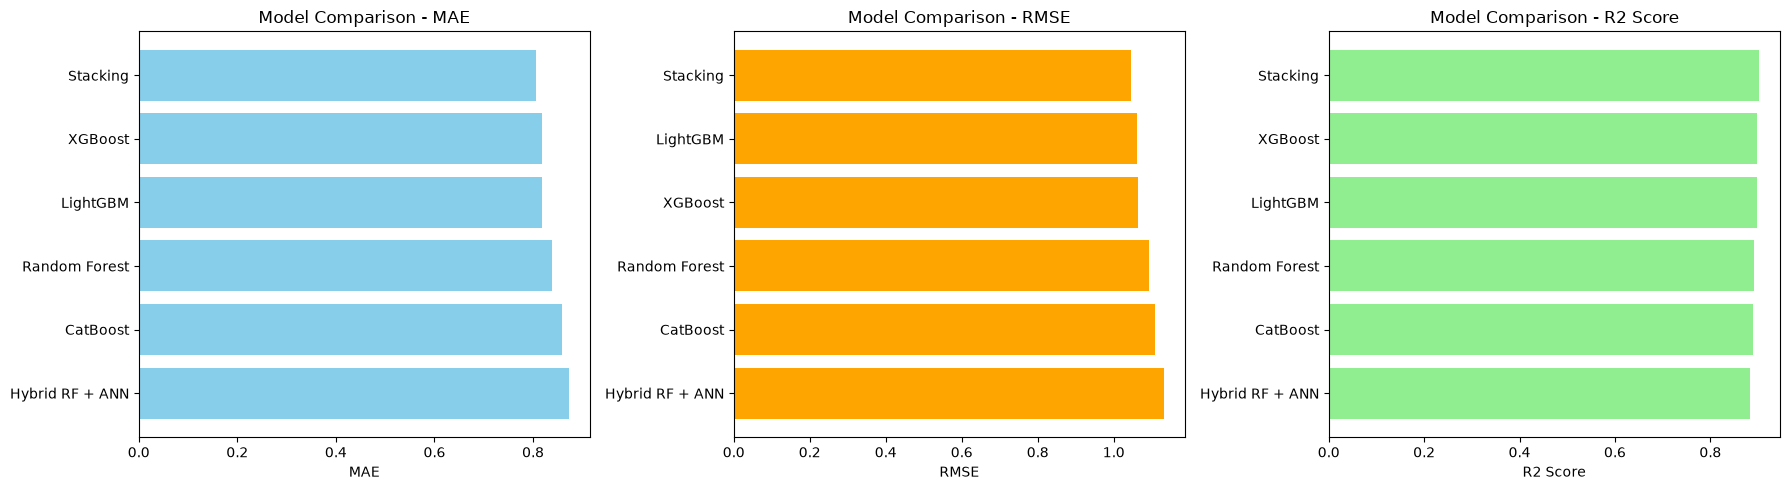

In [95]:
# Visualize Model Performance Comparison

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

metrics = ["MAE", "RMSE", "R2 Score"]
colors = ["skyblue", "orange", "lightgreen"]

for ax, metric, color in zip(axes, metrics, colors):
    sorted_results = results.sort_values(metric, ascending=(metric != "R2 Score"))

    ax.barh(sorted_results["Model"], sorted_results[metric], color=color)
    ax.set_title(f"Model Comparison - {metric}")
    ax.set_xlabel(metric)
    ax.invert_yaxis()

plt.tight_layout()
plt.show()

In [96]:
from sklearn.model_selection import GridSearchCV

# Random Forest Hyperparameter Tuning

rf_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestRegressor(
        random_state=42,
        n_jobs=-1
    ))
])

param_grid = {
    "model__n_estimators": [100, 200],
    "model__max_depth": [10, 20],
    "model__min_samples_split": [2, 5]
}

grid_search = GridSearchCV(
    rf_pipeline,
    param_grid,
    cv=3,
    scoring="neg_mean_absolute_error",
    n_jobs=1,
    verbose=1
)

grid_search.fit(X_train, y_train)

best_rf_model = grid_search.best_estimator_

print("Best Parameters:", grid_search.best_params_)
print("Best CV MAE:", round(-grid_search.best_score_, 3))

Fitting 3 folds for each of 8 candidates, totalling 24 fits
Best Parameters: {'model__max_depth': 20, 'model__min_samples_split': 5, 'model__n_estimators': 200}
Best CV MAE: 0.832


In [97]:
print("Best Parameters:", grid_search.best_params_)
print("Best CV MAE:", round(-grid_search.best_score_, 3))

Best Parameters: {'model__max_depth': 20, 'model__min_samples_split': 5, 'model__n_estimators': 200}
Best CV MAE: 0.832


In [98]:
xgb_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", XGBRegressor(
        random_state=42,
        n_jobs=-1
    ))
])

xgb_param_grid = {
    "model__n_estimators": [100, 200],
    "model__learning_rate": [0.05, 0.1],
    "model__max_depth": [4, 6]
}

xgb_grid = GridSearchCV(
    xgb_pipeline,
    xgb_param_grid,
    cv=3,
    scoring="neg_mean_absolute_error",
    n_jobs=1,
    verbose=1
)

xgb_grid.fit(X_train, y_train)

print("Best Parameters:", xgb_grid.best_params_)
print("Best CV MAE:", round(-xgb_grid.best_score_, 3))

Fitting 3 folds for each of 8 candidates, totalling 24 fits
Best Parameters: {'model__learning_rate': 0.1, 'model__max_depth': 6, 'model__n_estimators': 200}
Best CV MAE: 0.812


In [99]:
lgbm_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LGBMRegressor(
        random_state=42,
        n_jobs=-1,
        verbosity=-1
    ))
])

lgbm_param_grid = {
    "model__n_estimators": [100, 200],
    "model__learning_rate": [0.05, 0.1],
    "model__max_depth": [-1, 10]
}

lgbm_grid = GridSearchCV(
    lgbm_pipeline,
    lgbm_param_grid,
    cv=3,
    scoring="neg_mean_absolute_error",
    n_jobs=1,
    verbose=1
)

lgbm_grid.fit(X_train, y_train)

print("Best Parameters:", lgbm_grid.best_params_)
print("Best CV MAE:", round(-lgbm_grid.best_score_, 3))

Fitting 3 folds for each of 8 candidates, totalling 24 fits
Best Parameters: {'model__learning_rate': 0.05, 'model__max_depth': -1, 'model__n_estimators': 200}
Best CV MAE: 0.802


In [100]:
cat_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", CatBoostRegressor(
        random_seed=42,
        verbose=0
    ))
])

cat_param_grid = {
    "model__iterations": [200, 400],
    "model__learning_rate": [0.05, 0.1],
    "model__depth": [4, 6]
}

cat_grid = GridSearchCV(
    cat_pipeline,
    cat_param_grid,
    cv=3,
    scoring="neg_mean_absolute_error",
    n_jobs=1,
    verbose=1
)

cat_grid.fit(X_train, y_train)

print("Best Parameters:", cat_grid.best_params_)
print("Best CV MAE:", round(-cat_grid.best_score_, 3))

Fitting 3 folds for each of 8 candidates, totalling 24 fits
Best Parameters: {'model__depth': 6, 'model__iterations': 400, 'model__learning_rate': 0.05}
Best CV MAE: 0.795


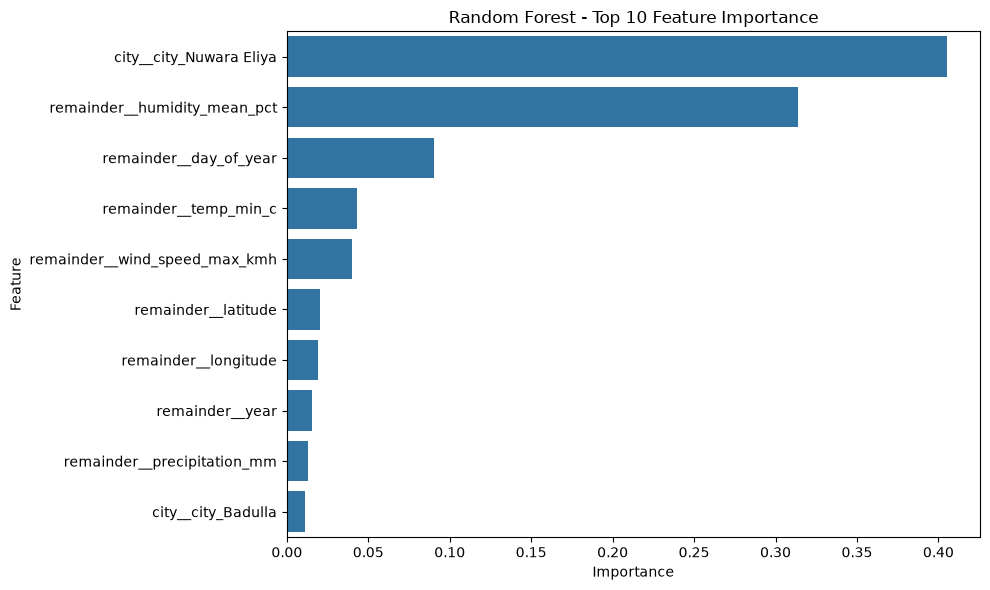

In [101]:
feature_names = rf_model.named_steps["preprocessor"].get_feature_names_out()

rf_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": rf_model.named_steps["model"].feature_importances_
}).sort_values("Importance", ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(data=rf_importance.head(10), x="Importance", y="Feature")
plt.title("Random Forest - Top 10 Feature Importance")
plt.tight_layout()
plt.show()

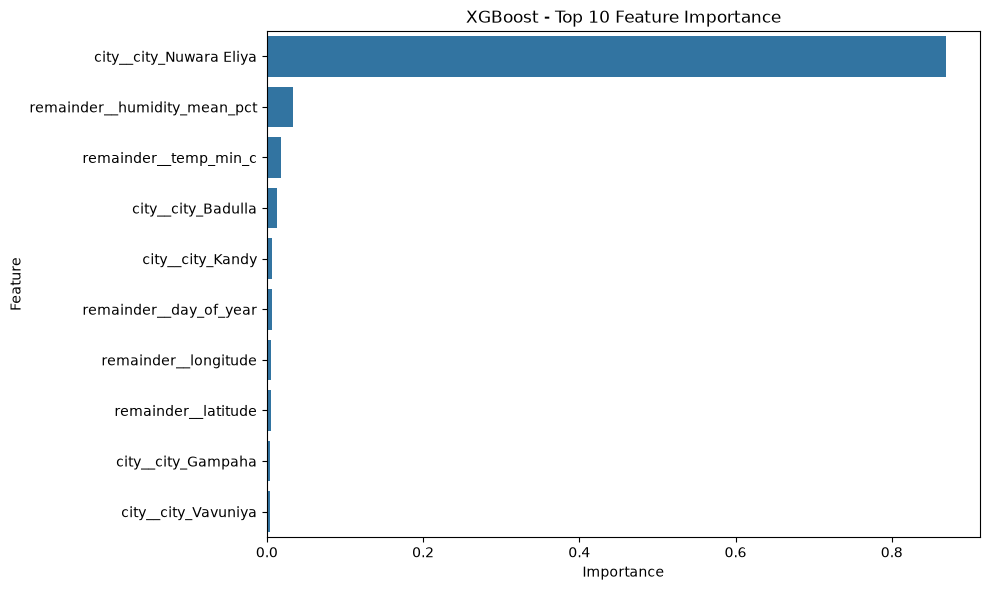

In [102]:
xgb_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": xgb_model.named_steps["model"].feature_importances_
}).sort_values("Importance", ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(data=xgb_importance.head(10), x="Importance", y="Feature")
plt.title("XGBoost - Top 10 Feature Importance")
plt.tight_layout()
plt.show()

In [103]:
print("Random Forest - Top 10 Features")
display(rf_importance.head(10))

print("XGBoost - Top 10 Features")
display(xgb_importance.head(10))

Random Forest - Top 10 Features


,Feature,Importance
19,city__city_Nuwara Eliya,0.405261
31,remainder__humidity_mean_pct,0.313771
35,remainder__day_of_year,0.090474
28,remainder__temp_min_c,0.043050
30,remainder__wind_speed_max_kmh,0.040298
26,remainder__latitude,0.020487
27,remainder__longitude,0.019225
32,remainder__year,0.015145
29,remainder__precipitation_mm,0.012954
2,city__city_Badulla,0.011135


XGBoost - Top 10 Features


,Feature,Importance
19,city__city_Nuwara Eliya,0.869485
31,remainder__humidity_mean_pct,0.033140
28,remainder__temp_min_c,0.018263
2,city__city_Badulla,0.012376
10,city__city_Kandy,0.006611
35,remainder__day_of_year,0.006271
27,remainder__longitude,0.005804
26,remainder__latitude,0.005131
6,city__city_Gampaha,0.004229
24,city__city_Vavuniya,0.003698


In [106]:
# Compare actual hyperparameter tuning results

tuning_results = pd.DataFrame({
    "Model": [
        "Random Forest",
        "XGBoost",
        "LightGBM",
        "CatBoost"
    ],
    "Best Parameters": [
        grid_search.best_params_,
        xgb_grid.best_params_,
        lgbm_grid.best_params_,
        cat_grid.best_params_
    ],
    "Best CV MAE": [
        -grid_search.best_score_,
        -xgb_grid.best_score_,
        -lgbm_grid.best_score_,
        -cat_grid.best_score_
    ]
})

tuning_results["Best CV MAE"] = tuning_results["Best CV MAE"].round(3)

tuning_results = tuning_results.sort_values(
    by="Best CV MAE"
).reset_index(drop=True)

tuning_results

,Model,Best Parameters,Best CV MAE
0,CatBoost,"{'model__depth': 6, 'model__iterations': 400, ...",0.795
1,LightGBM,"{'model__learning_rate': 0.05, 'model__max_dep...",0.802
2,XGBoost,"{'model__learning_rate': 0.1, 'model__max_dept...",0.812
3,Random Forest,"{'model__max_depth': 20, 'model__min_samples_s...",0.832


In [107]:
# Evaluate tuned models on the test dataset

tuned_models = {
    "Tuned Random Forest": grid_search.best_estimator_,
    "Tuned XGBoost": xgb_grid.best_estimator_,
    "Tuned LightGBM": lgbm_grid.best_estimator_,
    "Tuned CatBoost": cat_grid.best_estimator_
}

tuned_results = []

for name, model in tuned_models.items():

    predictions = model.predict(X_test)

    mae = mean_absolute_error(y_test, predictions)
    rmse = np.sqrt(mean_squared_error(y_test, predictions))
    r2 = r2_score(y_test, predictions)

    tuned_results.append({
        "Model": name,
        "MAE": mae,
        "RMSE": rmse,
        "R2 Score": r2
    })

tuned_results = pd.DataFrame(tuned_results)

tuned_results = tuned_results.round(3)

tuned_results.sort_values("MAE")

,Model,MAE,RMSE,R2 Score
1,Tuned XGBoost,0.814,1.066,0.897
2,Tuned LightGBM,0.817,1.058,0.899
3,Tuned CatBoost,0.822,1.067,0.897
0,Tuned Random Forest,0.837,1.090,0.892


### Analysis of Hyperparameter Tuning

To determine appropriate parameter settings for each model, hyperparameters were optimized using GridSearchCV with 3-fold cross-validation.

The results show that CatBoost achieved the lowest cross-validation Mean Absolute Error (MAE) of **0.795**, followed by LightGBM (0.802), XGBoost (0.812), and Random Forest (0.832).

A lower MAE indicates better prediction accuracy. Therefore, CatBoost achieved the best cross-validation performance among the four optimized models.

## Research Comparison: Random Forest vs Gradient Boosting

Random Forest and Gradient Boosting are two ensemble learning models used for prediction purposes.

### Random Forest (Bagging)

Random Forest is the bagging-based model of ensemble learning where multiple decision trees are utilized to construct one prediction model. In this case, each tree is built from the random samples of the training dataset and features. In order to make the prediction, the outputs of separate trees are aggregated.

**Pros:**
- Reduces the risk of overfitting in comparison with a single decision tree.
- Works with numerical and categorical features (after the appropriate preprocessing).
- Is able to consider nonlinear dependencies between features.
- Offers feature importance information.

**Cons:**
- Can consume more memory when using many trees.
- Can be less efficient than boosting models on structured datasets.
- The interpretability of the model becomes worse with the increasing number of trees.

### Gradient Boosting

Gradient Boosting is a boosting-based approach to ensemble learning where decision trees are built sequentially. The new tree tries to minimize the mistakes of the preceding trees. Some common implementations of gradient boosting include XGBoost, LightGBM, and CatBoost.

**Pros:**
- Provides the possibility to obtain high prediction accuracy on structured datasets.
- Is able to learn complex dependencies between input features.
- Provides an opportunity to tune parameters for improving the performance of the model.
- Can work with different types of predictive features.

**Cons:**
- Needs accurate tuning of the parameters.
- Can be computationally expensive.
- Can overfit if the model is not properly tuned.

### Comparison Based on This Project

In this research, Random Forest was compared to XGBoost, LightGBM, and CatBoost on the basis of the Sri Lankan weather dataset.

The baseline test showed that XGBoost provided MAE 0.818, LightGBM – MAE 0.819, while Random Forest provided MAE 0.839. CatBoost provided MAE 0.858.

Thus, XGBoost and LightGBM demonstrated the better performance compared to Random Forest in the baseline test evaluation. At the same time, CatBoost performed somewhat worse.

Therefore, the results show that the performance of ensemble learning models is dataset-dependent.

## Strengths and Limitations of Ensemble Learning for Different Data Types

Random Forest and Gradient Boosting are commonly used for structured tabular data. However, their suitability differs when working with image and text data.

### 1. Tabular Data

Tabular data contains structured information arranged in rows and columns, such as numerical and categorical features.

**Strengths:**
- Random Forest and Gradient Boosting perform well on structured datasets.
- They can learn nonlinear relationships between input features.
- They can handle different predictive features after appropriate preprocessing.
- They provide feature importance information to understand influential variables.

**Limitations:**
- Hyperparameter tuning may be required to achieve better performance.
- Missing values and categorical features may require preprocessing, depending on the model.
- Large ensembles can increase memory usage and computational time.

### 2. Image Data

Image data contains visual information such as shapes, edges, textures, and objects.

**Strengths:**
- Random Forest and Gradient Boosting can be applied to extracted image features.
- They can classify images when meaningful numerical features are provided.

**Limitations:**
- They do not naturally learn spatial patterns directly from raw images.
- Extracting useful image features may require additional processing.
- Convolutional Neural Networks (CNNs) are generally more suitable for automatically learning image features.

### 3. Text Data

Text data contains words, sentences, and documents.

**Strengths:**
- Random Forest and Gradient Boosting can work with numerical text representations such as TF-IDF features.
- They can be used for text classification tasks.
- They can learn patterns from extracted text features.

**Limitations:**
- Raw text must be converted into numerical features before these models can process it.
- They do not naturally understand language context and word relationships.
- Transformer-based models are generally more suitable for complex language understanding tasks.

### Overall Comparison

Random Forest and Gradient Boosting are particularly useful for structured tabular prediction problems. They can also be applied to image and text classification when suitable numerical features are extracted. However, deep learning approaches such as CNNs and Transformers are generally more suitable for learning complex image and language representations.

## Conclusion

In this project, six different machine learning approaches were used to predict daily maximum temperatures in Sri Lanka: Random Forest, XGBoost, LightGBM, CatBoost, Stacking, and a hybrid Random Forest–ANN model.

Among the baseline models, the Stacking model achieved the best test performance, with an MAE of 0.811, RMSE of 1.057, and R² score of 0.899.

Hyperparameter optimization was performed for four models using 3-fold cross-validation. The CatBoost model achieved the lowest cross-validation MAE of 0.795.

According to the feature importance analysis, city and humidity were identified as important predictive features.

Overall, this study demonstrates that ensemble learning techniques can effectively estimate daily maximum temperatures using the selected Sri Lankan weather dataset and input features.

## Generative AI Usage Documentation

Generative AI tools, such as ChatGPT, were used as supporting tools during the development of this project.

The following activities were supported by Generative AI:

1. **Code Assistance:** Used to understand Python code, identify coding errors, and improve code readability.
2. **Data Analysis:** Used to understand data preprocessing steps and interpret model evaluation results.
3. **Model Understanding:** Used to understand ensemble learning techniques, including Bagging, Boosting, and Stacking.
4. **Documentation Support:** Used to improve the explanations of model comparisons, hyperparameter tuning, and project findings.

Generative AI was used as an assistance tool. The project implementation and results were reviewed by the project developer.